# **Linear Regression Model: Box Office Revenue Prediction**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

This notebook marks the first modelling stage of my portfolio, focusing on building, training, and evaluating a baseline **Linear Regression** model using my currated and verified dataset of 902 movies prepared in `Datasetcleansing.ipynb` and stored in `movies.csv`. The objective is to investigate whether a movie's production budget alone can accurately predict its worldwide box office revenue.


### **Step 1 - Load My Cleaned Data & Perform Pearson Correlation Analysis (EDA)**

First, I load the verified dataset `movies.csv` containing the 902 movie records. Here I perform a **Pearson Correlation Analysis** between production **budget** and box office **revenue**, alongside a scatter plot, to verify whether there exists a positive linear relationship ($r > 0$) between the two fields.

In [16]:
import pandas as pand
import numpy as np
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plot
#load my data set
movies = pand.read_csv("movies.csv")
correlation = movies["budget"].corr(movies["revenue"])
print(f"Pearson Correlation Coefficient (r): {correlation:.4f}")

Pearson Correlation Coefficient (r): 0.6537


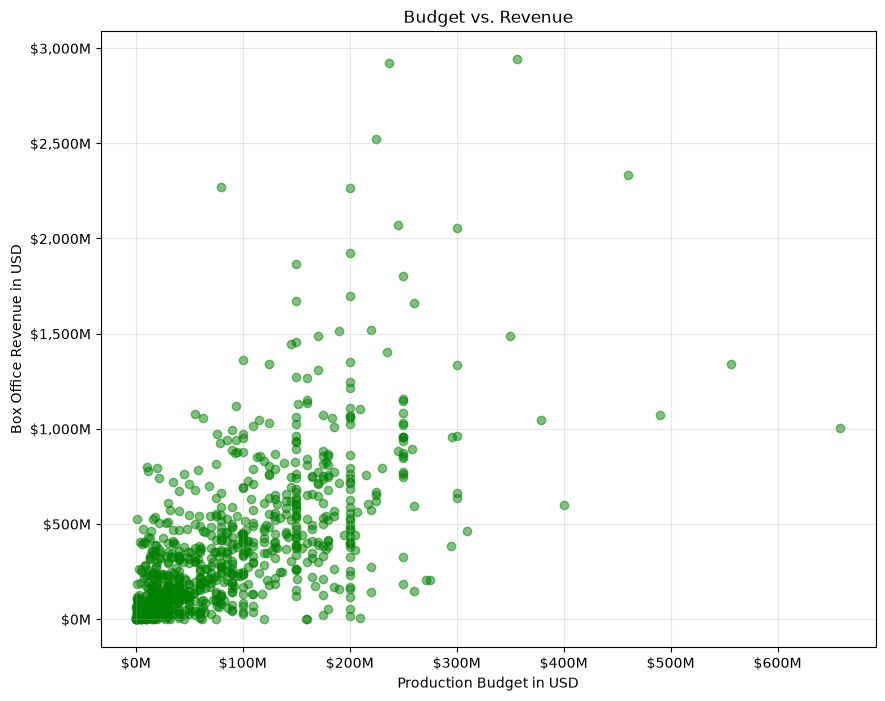

In [19]:
#displays the x and y nums as Millions rather than just 1 2 3 4 5 etc
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")
plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.5, color="green")

#applies the formatter to the x and y axis
plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.title("Budget vs. Revenue")
plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.grid(True, alpha=0.3)
plot.show()

Let's add our best fit line on this graph.

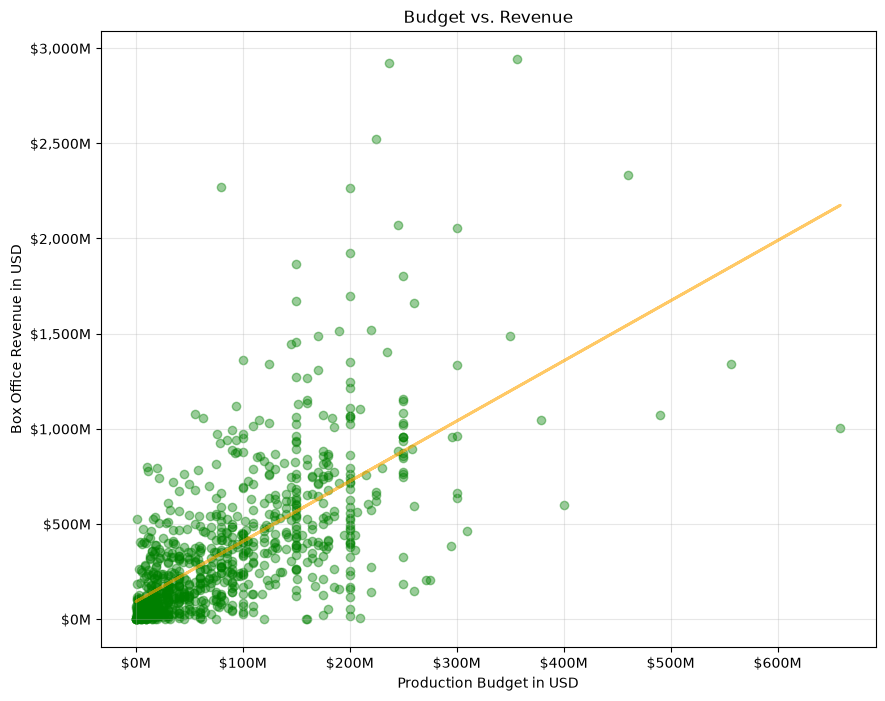

In [20]:
slope, yb = np.polyfit(movies["budget"], movies["revenue"], 1)

plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.4, color="green")
plot.plot(movies["budget"], slope * movies["budget"] + yb, alpha=0.6, color="orange", linewidth=2)

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.title("Budget vs. Revenue")
plot.xlabel("Production Budget in USD")
plot.ylabel("Box Office Revenue in USD")
plot.grid(True, alpha=0.3)
plot.show()

### **Step 2 - Data Preprocessing**

Before training the model, I need to prepare the dataset:

* **Field Selection:** Only **budget** and **revenue** are needed.

* **Train/Test Split:** Split the data into an 80/20 training testing split using `random_state=42` so I know all models are tested on the exact same movies.

* **Z-Score Normalisation:** Scale using standard deviation and training set mean as discussed in the lectures.

In [24]:
from sklearn.model_selection import train_test_split

x = movies[["budget"]]
y = movies["revenue"]
#create the training and test split in an 80/20 ratio
xtrainingset, xtestingset, ytrainingset, ytestingset = train_test_split(x, y, test_size=0.2, random_state=42)

Now that i have divided the movies dataset into its training and testing sets it is time to apply Z-score normalisation using the training set's mean and standard deviation.

In [31]:
# i use built in functions to get the mean and standard deviation of budget
mean = xtrainingset.mean()
stddev = xtrainingset.std()

xtrainingsetformulated = ((xtrainingset - mean)/stddev)
xtestingsetformulated = ((xtestingset - mean)/stddev)

print(f"training set: {len(xtrainingsetformulated)}")
print(f"testing set: {len(xtestingsetformulated)}")
#print mean and standard deviation to 2 decimal places
print(f"Training Mean Budget: ${mean['budget']:,.2f}")
print(f"Training Std Dev: ${stddev['budget']:,.2f}")

training set: 721
testing set: 181
Training Mean Budget: $83,342,429.69
Training Std Dev: $80,553,668.87


### **Step 3 - Model Training**

Now that i have set up my training and testing set and scaled them via Z-Score normalisation, I call sci kits Linear Regression model and fit it on my data.

In [ ]:
from sklearn.linear_model import LinearRegression